# Predicting upsets against ATP top-20 players
CT4101 Milestone 2: data exploration and baseline. Anna Kramska, 26100706

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/atp_tennis.csv")
print(df.shape)
df.head()

(68814, 17)


,Tournament,Date,Series,Court,Surface,Round,Best of,Player_1,Player_2,Winner,Rank_1,Rank_2,Pts_1,Pts_2,Odd_1,Odd_2,Score
0,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,Arthurs W.,Gambill J.M.,Gambill J.M.,105,58,-1,-1,-1.0,-1.0,6-3 6-7 4-6
1,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,Balcells J.,Henman T.,Henman T.,218,11,-1,-1,-1.0,-1.0,4-6 6-7
2,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,Clement A.,Enqvist T.,Enqvist T.,56,5,-1,-1,-1.0,-1.0,3-6 3-6
3,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,Dosedel S.,Ljubicic I.,Dosedel S.,63,77,-1,-1,-1.0,-1.0,6-4 6-2
4,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,Draper S.,Norman M.,Norman M.,155,15,-1,-1,-1.0,-1.0,4-6 4-6


In [2]:
# -1 means missing
df = df.replace(-1, np.nan)

# date to actual dates
df["Date"] = pd.to_datetime(df["Date"])

# check for types, missing, duplicates
df.info()
print(df.isna().sum())
print(df.duplicated().sum())
# which years are missing points
print(df[df["Pts_1"].isna()]["Date"].dt.year.value_counts().sort_index())

<class 'pandas.DataFrame'>
RangeIndex: 68814 entries, 0 to 68813
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Tournament  68814 non-null  str           
 1   Date        68814 non-null  datetime64[us]
 2   Series      68814 non-null  str           
 3   Court       68814 non-null  str           
 4   Surface     68814 non-null  str           
 5   Round       68814 non-null  str           
 6   Best of     68814 non-null  int64         
 7   Player_1    68814 non-null  str           
 8   Player_2    68814 non-null  str           
 9   Winner      68814 non-null  str           
 10  Rank_1      68800 non-null  float64       
 11  Rank_2      68802 non-null  float64       
 12  Pts_1       53162 non-null  float64       
 13  Pts_2       53161 non-null  float64       
 14  Odd_1       65032 non-null  float64       
 15  Odd_2       65034 non-null  float64       
 16  Score       68814 non-null  str  

## Data audit
- 68,814 matches, 17 columns
- Ranks are missing for 26 rows, so I'll drop those
- Points are missing for all matches from 2000 to 2004 and about half of 2005, so I won't use points
- Odds are missing for about 3,780 rows. Odds are only for comparing later, not a feature
- No duplicates

In [3]:
df = df.dropna(subset=["Rank_1", "Rank_2"])

# favorite = better rank, underdog = worse rank
df["fav_rank"] = df[["Rank_1", "Rank_2"]].min(axis=1)
df["dog_rank"] = df[["Rank_1", "Rank_2"]].max(axis=1)
df["rank_gap"] = df["dog_rank"] - df["fav_rank"]

matches = df[(df["fav_rank"] <= 20) & (df["rank_gap"] >= 20)].copy()

# upset = underdog won
matches["winner_rank"] = matches["Rank_2"]
matches.loc[matches["Winner"] == matches["Player_1"], "winner_rank"] = matches["Rank_1"]
matches["upset"] = (matches["winner_rank"] == matches["dog_rank"]).astype(int)

print(matches.shape)

(19192, 22)


upset
0    0.771415
1    0.228585
Name: proportion, dtype: float64


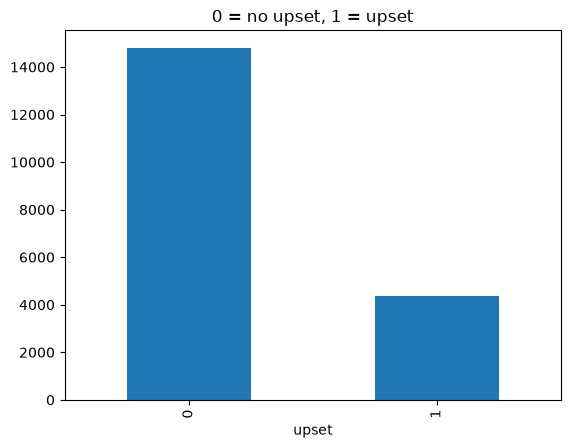

count    19192.000000
mean        88.695759
std        103.952325
min         21.000000
25%         45.000000
50%         65.000000
75%         99.000000
max       4915.000000
Name: dog_rank, dtype: float64


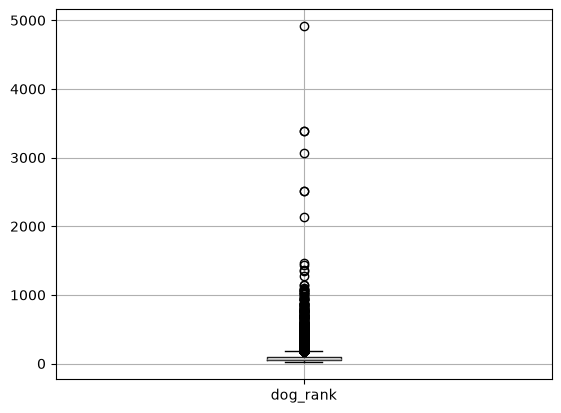

In [4]:
# target
print(matches["upset"].value_counts(normalize=True))
matches["upset"].value_counts().plot(kind="bar", title="0 = no upset, 1 = upset")
plt.show()

# outliers
print(matches["dog_rank"].describe())
matches.boxplot(column="dog_rank")
plt.show()

## Target and outliers
- One row is one match, and the same players show up in many rows
- 19,192 matches fit my question. 23% are upsets, so the classes aren't balanced
- Most underdogs are ranked 45 to 99, but some go up to 4,915. These are real players like qualifiers, not mistakes, so I'm keeping them

In [5]:
# old level names changed in 2009
matches["Series"] = matches["Series"].replace({"International": "ATP250", "International Gold": "ATP500", "Masters": "Masters 1000"})

# split by year
year = matches["Date"].dt.year
train = matches[year <= 2020]
val = matches[(year >= 2021) & (year <= 2022)]
test = matches[year >= 2023]

print(len(train), len(val), len(test))
print(train["upset"].mean(), val["upset"].mean(), test["upset"].mean())

15122 1293 2777
0.2282105541595027 0.23356535189481825 0.22830392509902772


## Train/test split
- Split by year so the model never trains on future matches (train 2000 to 2020, validation 2021 to 2022, test 2023 to 2026)
- Test is only used at the end
- Not using Score since it's only known after the match

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = ["fav_rank", "dog_rank", "rank_gap"]
cat_cols = ["Surface", "Court", "Series", "Round", "Best of"]

num_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
cat_pipe = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))
prep = ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])

# fit on train only
prep.fit(train[num_cols + cat_cols])
print(prep.transform(train[num_cols + cat_cols]).shape)

(15122, 24)


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

y_val = val["upset"]

# always guess no upset
no_upset = np.zeros(len(val))
print(accuracy_score(y_val, no_upset), precision_score(y_val, no_upset, zero_division=0), recall_score(y_val, no_upset))

# baseline: logistic regression on just the ranks
rank_cols = ["fav_rank", "dog_rank"]
baseline = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))
baseline.fit(train[rank_cols], train["upset"])
pred = baseline.predict(val[rank_cols])
print(accuracy_score(y_val, pred), precision_score(y_val, pred), recall_score(y_val, pred))

0.7664346481051817 0.0 0.0
0.5692188708430008 0.2926829268292683 0.5960264900662252


## Baseline results
- Always guessing "no upset" gets 77% accuracy, but 0 precision and 0 recall since it never catches an upset
- Logistic regression on ranks is 57% accuracy, 29% precision, 60% recall
- The baseline catches about 60% of upsets, but most of its upset guesses are wrong
- I used class_weight="balanced" because without it the model never predicted an upset
- The pipeline is set up now and I will use it in Milestone 3